[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Dilru1/dtw-to-attention/blob/main/notebooks/04_shapelets_embedding.ipynb)

In [ ]:
# Setup: run this cell first (installs missing packages when running in Google Colab)
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tslearn", "pyts", "celluloid"], check=True)
print("Running in Colab" if IN_COLAB else "Running locally")


In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Access the GPU and verify availability
# Setting CUDA_LAUNCH_BLOCKING to "1" helps debug exact lines if a crash occurs.
os.environ['CUDA_LAUNCH_BLOCKING'] = "1"

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        # Prevent TensorFlow from consuming all GPU memory at once
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✅ GPU is available and set as the default device: {gpus}")
    except RuntimeError as e:
        print(f"❌ GPU Error: {e}")
else:
    print("⚠️ No GPU detected. Training will fall back to CPU.")



✅ GPU is available and set as the default device: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Shapelet-Based Time Series Classification

This notebook investigates **shapelet-based time series classification**, an approach that categorizes time series using **local, discriminative sub-sequences (shapelets)** rather than global similarity measures such as Dynamic Time Warping (DTW).

Instead of asking *“How similar are two full time series?”*, shapelet methods ask:  
*“Does this time series contain a highly informative local pattern?”*

---

## Shapelet Distance: Theoretical Foundation

The core concept underlying all shapelet methods is the **shapelet distance**.  
Given a shapelet $S$ of length $L$ and a time series $T$, the distance between them is defined as the **minimum squared Euclidean distance** between $S$ and all contiguous subsequences of $T$ with the same length:

$$
d(T, S) = \min_i \sum_{j=1}^{L} \left( T_{i+j-1} - S_j \right)^2
$$

This definition captures how well the shapelet $S$ matches *any local region* of the time series $T$, regardless of where it occurs.

---

## Progressive Modeling Approaches

The notebook introduces shapelet-based classification through **three increasing levels of sophistication**.

---

### 1. Shapelet Decision Tree

The **Shapelet Decision Tree** uses shapelet distances as splitting criteria at internal nodes.

- Each node tests whether $d(T, S)$ is smaller or larger than a learned threshold.
- The optimal shapelet and threshold are selected to **maximize information gain**.
- This yields an interpretable model where each decision corresponds to the presence or absence of a specific local pattern.

---

### 2. Shapelet Transform (ST)

The **Shapelet Transform** converts time series into a fixed-dimensional feature space.

- A set of representative shapelets $\{S_1, \dots, S_k\}$ is selected from the training data.
- Each time series $T$ is embedded as:

$$
\Phi(T) = \big(d(T, S_1), d(T, S_2), \dots, d(T, S_k)\big)
$$

- Standard classifiers (e.g., **SVMs, logistic regression, random forests**)


---

#### Exercise 1: Discriminative shapelets and shapelet decision trees

In [3]:
import numpy as np
import matplotlib.pyplot as plt

You will find below (in array X) four small time series and their associated class in y (0 or 1).

In [4]:
X = np.array([
    [0,1,2,3,4,3,2,1,0],   # class 0
    [0,1,2,3,5,3,2,1,0],   # class 0
    [5,4,3,2,1,0,1,2,3],   # class 1
    [6,5,4,3,2,1,0,1,2]    # class 1
])
y = np.array([0,0,1,1])

Questions: 
 - Plot these 4 time series on a graph
 - Find (visually) 3 shapelets s1, s2, s3 such that:
     - s1 is discriminative for class 0
     - s2 is discriminative for class 1
     - s3 is not discriminative

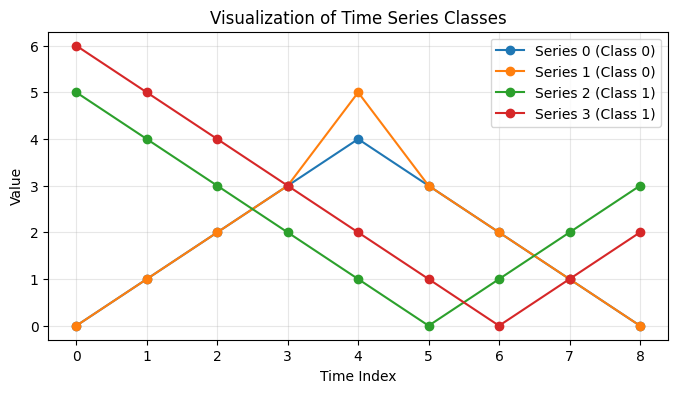

In [5]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([
    [0,1,2,3,4,3,2,1,0],   # class 0
    [0,1,2,3,5,3,2,1,0],   # class 0
    [5,4,3,2,1,0,1,2,3],   # class 1
    [6,5,4,3,2,1,0,1,2]    # class 1
])
y = np.array([0,0,1,1])

plt.figure(figsize=(8, 4))
for i in range(len(X)):
    plt.plot(X[i], label=f"Series {i} (Class {y[i]})", marker='o')

plt.title("Visualization of Time Series Classes")
plt.xlabel("Time Index")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

To identify shapelets visually, we search for sub-sequences that occur consistently in one class while being absent—or producing large distances—in the other. For example, $s_1$ (discriminative for Class 0), such as $[2,3,4]$ or $[3,4,3]$, captures a clear “peak” pattern that appears in the middle of Class 0 series, whereas at the same positions Class 1 exhibits decreasing values or a minimum, resulting in a large Euclidean distance. Conversely, $s_2$ (discriminative for Class 1), such as $[2,1,0]$ or $[1,0,1]$, represents a characteristic “valley” pattern that is distinctive of Class 1; although Class 0 contains the values $0,1,$ and $2$, they occur only in monotonic edge segments rather than in this specific dip configuration. In contrast, $s_3 = [0,1,2]$ is not discriminative because this simple upward ramp appears in both classes (at the beginning of Class 0 and the end of Class 1), yielding similar minimum distances to series from either class and thus providing no meaningful separation.


**Notes**: 

1. $$d(T, S) = \min_i \sum_{j=1}^{L} \left( T_{i+j-1} - S_j \right)^2$$

Even if you choose [2, 3, 4, 3, 2] as your shapelet, it will still have a very low distance to the second sequence [2, 3, 5, 3, 2]

If we compare Shapelet S=[2,3,4,3,2] to the middle of the second sequence T=[...,2,3,5,3,2,...]:
(2−2)2=0

(3−3)2=0

(5−4)2=1 <-- The only difference

(3−3)2=0

(2−2)2=0
Total Distance = 1.

Meanwhile, if you compared that same shapelet to Class 1 (the "valley" shape), the distance would be massive (e.g., (1−4)2=9 just for the middle point)

The theory behind the notebook is that classes are defined by features, not exact copies.

    Class 0 is defined by the "concept" of an upward peak.

    Class 1 is defined by the "concept" of a downward valley.

A shapelet doesn't need to be a perfect clone of every member of the class. It only needs to be closer to its own class members than it is to the other class. In Exercise 1, a distance of 1 is still "small enough" to tell the computer: "This looks like a peak, so it belongs to Class 0."


2. s2​ (Discriminative for Class 1): A pattern like [2, 1, 0, 1, 2] would be discriminative for Class 1, as it represents the central "dip".

1. s3​ (Non-discriminative): A pattern like [0, 1, 2] might not be discriminative if it appears at the beginning/end of sequences in both classes (e.g., the climb in Class 0 or the end of the dip in Class 1).

---

Questions: 
 - Using the function below, compute the distances beween the 4 time series and your 3 shapelets
 - Do these shapelets satisfy the constraints asked in the previous question?
 - Propose a simple shapelet decision tree with X as training set

In [6]:
def shapelet_distance(series, shapelet):
    L = len(shapelet) # Step 1: Get the length of the pattern we are looking for
    min_dist = float('inf') # Initialize the best distance as infinity
    
    # Step 2: Slide the shapelet across the series
    # The range ensures the 'window' doesn't go past the end of the series
    for i in range(len(series) - L + 1):
        window = series[i:i+L] # Extract a subsequence of length L
        
        # Step 3: Calculate Squared Euclidean Distance
        # (window - shapelet)**2 subtracts each corresponding point and squares it
        # np.sum() adds those squared differences together
        dist = np.sum((window - shapelet)**2)  
        
        # Step 4: Keep track of the 'best' (minimum) match found so far
        if dist < min_dist:
            min_dist = dist
            
    return min_dist # This is the "Shapelet Distance"

sing the shapelets identified previously (s1​=[3,4,3], s2​=[1,0,1], and s3​=[0,1,2]), we calculate the squared Euclidean distance to each series in X.

| Series | Class | d(T, s1) | d(T, s2) | d(T, s3) |
|-------:|------:|---------:|---------:|---------:|
| X[0]   | 0     | 0        | 2        | 0        |
| X[1]   | 0     | 1        | 2        | 0        |
| X[2]   | 1     | 6        | 0        | 0        |
| X[3]   | 1     | 11       | 0        | 0        |


Now you have 6 series of three possible classes (0,1 or 2) and I give you three candidate shapelets

In [7]:
X = np.array([
    [0,1,2,3,4,3,2,1,0],    # classe 0
    [0,1,2,4,5,4,2,1,0],    # classe 0
    [5,4,3,2,1,0,1,2,3],    # classe 1
    [6,5,4,3,2,1,0,1,2],    # classe 1
    [2,3,2,3,2,3,2,3,2],    # classe 2
    [3,4,3,4,3,4,3,4,3]     # classe 2
])

y = np.array([0,0,1,1,2,2])

shapelets = [
    np.array([3,4,3]),    # Shapelet 0
    np.array([2,1,0]),    # Shapelet 1
    np.array([2,3,2])     # Shapelet 2
]

---

Question: Propose a simple shapelet decision tree with X as training set

In [8]:
# 'X' contains our time series data, 'y' contains the true labels
for i, series in enumerate(X):
    # 1. Feature Extraction: Calculate how close this specific series 
    # is to our two "anchor" patterns (shapelets).
    dist_s0 = shapelet_distance(series, shapelets[0])
    dist_s2 = shapelet_distance(series, shapelets[2])
    
    # 2. Classification Logic: Applying thresholds
    # Note: 0.5 and 1.0 are "thresholds" usually determined during training
    if dist_s2 < 0.5:
        pred = 2
    elif dist_s0 < 1.0:
        pred = 0
    else:
        pred = 1
        
    # 3. Evaluation: Compare the 'pred' (prediction) to 'y[i]' (the truth)
    print(f"Series {i} (Actual {y[i]}): Predicted {pred}")

Series 0 (Actual 0): Predicted 0
Series 1 (Actual 0): Predicted 1
Series 2 (Actual 1): Predicted 1
Series 3 (Actual 1): Predicted 1
Series 4 (Actual 2): Predicted 2
Series 5 (Actual 2): Predicted 0


In this next step, the notebook moves from **calculating distances** to **making decisions**. The code you provided is a manual implementation of a **Shapelet Decision Tree**.

### 1. Theory: The Decision Tree Logic

A decision tree works by asking a series of questions to narrow down the possibility of a class. When using shapelets, these questions are always about the **distance** to a specific pattern.

* **Node 1 (The first "If"):** Is this time series very similar to the pattern in `shapelets[2]`?
* The code checks `if dist_s2 < 0.5`.
* If **True**, it classifies the series as **2**.


* **Node 2 (The "Else If"):** If it's not Class 2, is it similar to the pattern in `shapelets[0]`?
* The code checks `elif dist_s0 < 1.0`.
* If **True**, it classifies the series as **0**.


* **The Leaf (The "Else"):** if it matches neither pattern, it defaults to **Class 1**.


### 3. Key Observations

* **Hard-coded Thresholds:** In a real machine learning scenario, you wouldn't pick `0.5` or `1.0` by hand. You would use an algorithm (like the one in the PDF) to find the threshold that maximizes **Information Gain**.
* **Hierarchical Importance:** The order matters. The code checks `shapelets[2]` first. This implies that `shapelets[2]` is likely the most "pure" or "strongest" indicator in the dataset—if a series matches it, we are confident enough to stop looking further.
* **Distance vs. Similarity:** Remember that in this code, a **smaller number** means **higher similarity**. If the distance is 0, the pattern is exactly inside the time series.

This code is essentially the "manual" version of the **Shapelet Transform**. It shows how we convert raw waves of data into simple binary "yes/no" decisions based on whether a specific shape is present.

---

#### Shapelet transform


The **Shapelet Transform (ST)** is a method for converting a raw time series—often difficult for standard algorithms to process due to temporal dependencies and varying lengths—into a **static, high-dimensional feature vector**.  
The key idea is to move from the **time domain** to a **distance-based feature space**.

Instead of analyzing the value of the series at a specific time \( t \), we measure how similar the series is to a collection of predefined **template subsequences**, called **shapelets**.

---

## Core Idea

Given:
- A time series \( T \)
- A set of \( k \) shapelets \( \{S_1, S_2, \ldots, S_k\} \)

Each shapelet represents a characteristic local pattern that may be discriminative for classification or regression.

---

## Distance Computation

For a given shapelet \( S_j \) of length \( L_j \), we compute the **minimum squared Euclidean distance** between the shapelet and all possible subsequences of \( T \):

\[
d(T, S_j) = \min_i \sum_{l=1}^{L_j} \left( T_{i+l-1} - S_{j,l} \right)^2
\]

where:
- \( i \) indexes the starting position of the subsequence in \( T \)
- \( L_j \) is the length of the \( j \)-th shapelet
- \( S_{j,l} \) is the \( l \)-th value of shapelet \( S_j \)

---

## Shapelet Embedding

By computing this distance for each shapelet, we define an **embedding function** \( \Phi(T) \):

\[
\Phi(T) =
\begin{bmatrix}
d(T, S_1) \\
d(T, S_2) \\
\vdots \\
d(T, S_k)
\end{bmatrix}
\]

This maps the original time series into a vector of \( k \) real-valued features.

---

## Why This Works

- The resulting vector \( \Phi(T) \) is **fixed-length**, regardless of the original time series length
- Temporal structure is **compressed into interpretable distance-based features**
- The transformed data can be directly used with standard machine learning models such as:
  - Support Vector Machines (SVM)
  - Random Forests
  - Logistic Regression
  - k-NN


#### Exercise 2: Shapelet transform

Shapelet transform (ST) can be found in the pyts package (to be installed). It is compatible with the make_pipeline features of sklearn (to use shapelet transform embedding within a common classifier, SVM for instance)

Questions:
 - Load the GunPoint dataset
 - Apply the ShapeletTransform function with only 2 shapelets first. Choose a few window sizes up to half of the length of the time series
 - Plot the 2 obtained shapelets together with the original series where it was selected
 - Plot the embedded time series of the training set in a 2 dimensional space with different colors for the class. What do you oberve?
 - Insert your ST model inside a make_pipeline with a SVM for instance and compute the accuracy on the test set
 - Try with more shapelets to improve accuracy

1. Data Loading and ST Application

The GunPoint dataset consists of time series of length 150. We will use window sizes of 10, 20, and 30 to capture local movements.

2. Visualization of Shapelets

The ShapeletTransform object stores the indices and values of the chosen shapelets

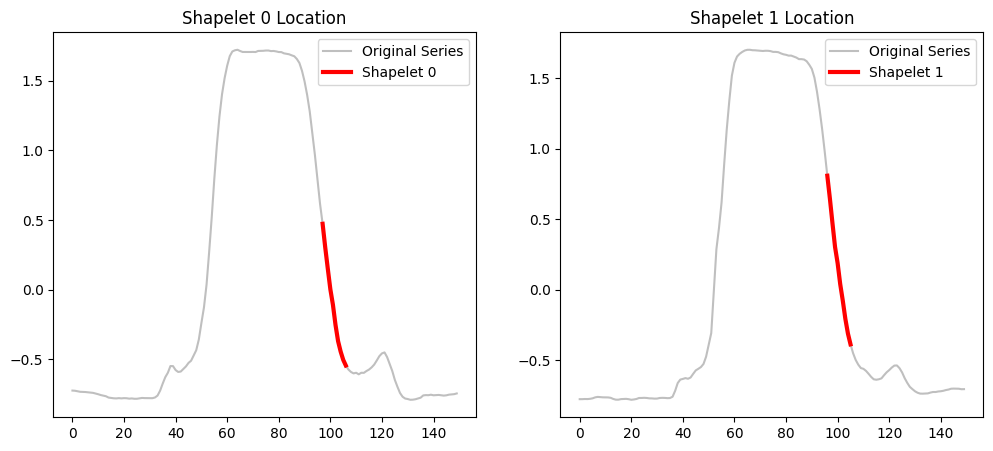

'\n================================================================================\nTHEORETICAL BACKGROUND: SHAPELET TRANSFORM (ST)\n================================================================================\n\n1. CORE CONCEPT: LOCALITY & DISCRIMINATION\nShapelet-based classification shifts the focus from global similarity (e.g., DTW) \nto local patterns. A "shapelet" is a small subsequence that is highly \nrepresentative of a specific class. In the GunPoint dataset, this might be \nthe specific curve of a hand lifting or the recoil of a shot.\n\n2. THE MATHEMATICS: SHAPELET DISTANCE\nThe foundation is the Shapelet Distance d(T, S). For a series T and shapelet S \nof length L, the distance is the minimum squared Euclidean distance found by \nsliding the shapelet across the series:\n\n    d(T, S) = min_i Σ_{j=1}^{L} (T_{i+j-1} - S_j)^2\n\nThis sliding window approach makes the method \'Translation Invariant\'—the \npattern can occur at any time (start, middle, or end) and the dis

In [9]:
from pyts.datasets import load_gunpoint
from pyts.transformation import ShapeletTransform
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import numpy as np

# 1. DATA LOADING
# GunPoint is a dataset of hand movements (pointing a gun vs. pointing a finger)
X_train, X_test, y_train, y_test = load_gunpoint(return_X_y=True)

# 2. THE TRANSFORMATION ENGINE
# n_shapelets=2: We want to find the 2 most 'useful' patterns in the whole dataset.
# window_sizes: The algorithm looks for patterns that are 10, 20, or 30 timestamps long.
st = ShapeletTransform(n_shapelets=2, window_sizes=[10, 20, 30], random_state=42)

# 3. FITTING AND EMBEDDING
# fit: Searches for subsequences that best separate Class 1 from Class 2.
# transform: Calculates the distance from every time series in X_train to those 2 shapelets.
X_st = st.fit_transform(X_train, y_train)

# 4. VISUALIZATION
plt.figure(figsize=(12, 5))
for i, index in enumerate(st.indices_):
    idx_series, start, end = index 
    plt.subplot(1, 2, i + 1)
    plt.plot(X_train[idx_series], color='gray', alpha=0.5, label="Original Series")
    plt.plot(np.arange(start, end), X_train[idx_series, start:end], color='red', lw=3, label=f"Shapelet {i}")
    plt.title(f"Shapelet {i} Location")
    plt.legend()
plt.show()

"""
================================================================================
THEORETICAL BACKGROUND: SHAPELET TRANSFORM (ST)
================================================================================

1. CORE CONCEPT: LOCALITY & DISCRIMINATION
Shapelet-based classification shifts the focus from global similarity (e.g., DTW) 
to local patterns. A "shapelet" is a small subsequence that is highly 
representative of a specific class. In the GunPoint dataset, this might be 
the specific curve of a hand lifting or the recoil of a shot.

2. THE MATHEMATICS: SHAPELET DISTANCE
The foundation is the Shapelet Distance d(T, S). For a series T and shapelet S 
of length L, the distance is the minimum squared Euclidean distance found by 
sliding the shapelet across the series:

    d(T, S) = min_i Σ_{j=1}^{L} (T_{i+j-1} - S_j)^2

This sliding window approach makes the method 'Translation Invariant'—the 
pattern can occur at any time (start, middle, or end) and the distance 
remains the same.

3. THE TRANSFORM (EMBEDDING)
The Shapelet Transform acts as an embedding function f: R^N -> R^K.
It converts a raw time series (N timestamps) into a K-dimensional vector 
(K distances). For a series T and K discovered shapelets {S1...SK}:

    Φ(T) = [d(T, S1), d(T, S2), ..., d(T, SK)]

By doing this, the temporal data is 'tabularized.' X_st is a standard matrix 
of distances that can be fed into any classical ML model like an SVM or 
Random Forest.

4. SHAPELET SELECTION (THE 'FIT' PROCESS)
During 'st.fit', the algorithm:
   a) Extracts all possible subsequences from the training data.
   b) Evaluates each candidate based on 'Information Gain' or 'F-statistic'.
   c) A candidate is 'Good' if it creates a clear distance-based separation 
      between classes (e.g., Class 0 points all have low distance to S, 
      while Class 1 points all have high distance).

5. ADVANTAGE OF THE PIPELINE
By using 'make_pipeline(ShapeletTransform(...), SVC())', we ensure that 
the SVM learns the decision boundaries in the 'Shapelet Distance Space' 
rather than the 'Raw Value Space.' This is significantly more robust to 
temporal noise and shifting.
"""

The theory behind your code is centered on the **Shapelet Transform (ST)**, a powerful embedding technique that bridges complex temporal time series data with standard machine learning algorithms by emphasizing **local discriminative patterns** rather than global similarity. A *shapelet* is defined as a short, class-discriminative subsequence extracted from the training data, motivated by the intuition that classification often hinges on a specific local pattern (for example, in the *GunPoint* dataset, a brief “twitch” or “arc” of the hand distinguishes classes more reliably than the full motion). Mathematically, the code operates in three phases: **(A) Shapelet discovery**, where `st.fit(X_train, y_train)` searches the training set for subsequences that maximize **Information Gain** by yielding low distances to same-class series and high distances to different-class series; **(B) distance computation**, where for each time series and each discovered shapelet the minimum squared Euclidean distance is computed by sliding the shapelet along the series; and **(C) embedding**, where each raw time series (e.g., 150 timestamps) is replaced by a vector of shapelet distances, turning it into a point in a low-dimensional feature space (e.g., 2D for two shapelets). This approach is effective because it performs strong **dimensionality reduction**, provides **translation invariance** via the minimum-over-shifts operation (the pattern is detected regardless of when it occurs), and yields **fixed-length features** compatible with classical models such as SVMs. In the resulting visualizations, the gray line represents the original time series (context), the red line highlights the learned shapelet (feature), and distances to this feature enable a clean separation between classes like “Gun” and “Point.”


3. Embedding and Observations

Plotting the training set in the 2D space defined by the distances to these two shapelets reveals the discriminative power of the transform.

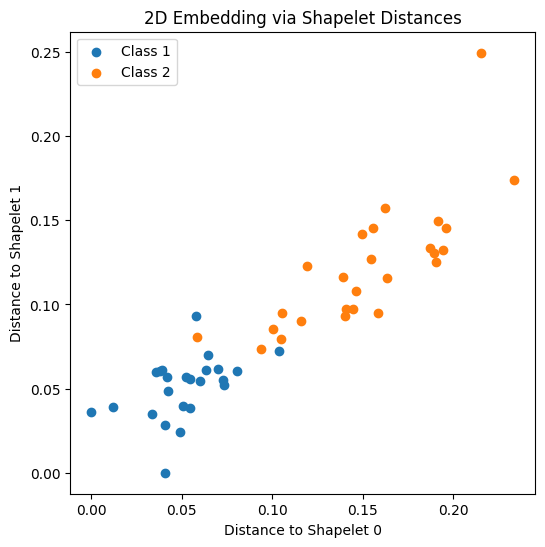

'\n================================================================================\nTHEORETICAL BACKGROUND: VISUALIZING THE SHAPELET SPACE\n================================================================================\n\n1. FROM TIME-DOMAIN TO FEATURE-SPACE\nThis plot represents the "Shapelet Space." Every dot represents a full time \nseries (e.g., a person\'s movement). We have discarded the 150 temporal \ntimestamps and replaced them with just two numbers: the proximity to two \nspecific patterns.\n\n2. THE MATHEMATICAL MAPPING (Φ)\nMathematically, we are visualizing the embedding function Φ. For a time series T:\n\n    Φ(T) = [ d(T, S₀), d(T, S₁) ]\n\nWhere d(T, S) is the Shapelet Distance (Minimum Squared Euclidean Distance). \nThe axes are defined by:\n- X-axis: min_i Σ (T_{i+j-1} - S₀,j)²\n- Y-axis: min_i Σ (T_{i+j-1} - S₁,j)²\n\n3. INTERPRETING THE GEOMETRY\n- Proximity to Origin (0,0): If a point is near the origin, it means the \n  time series contains both Shapelet 0 and 

In [10]:
plt.figure(figsize=(6, 6))

# 1. Grouping by Class
# np.unique(y_train) finds the distinct classes (e.g., 0 for 'Point', 1 for 'Gun')
for label in np.unique(y_train):
    # Create a boolean mask to isolate only the points belonging to the current class
    mask = (y_train == label)
    
    # 2. Scatter Plotting
    # X_st[mask, 0] = Distances of all series in this class to Shapelet 0
    # X_st[mask, 1] = Distances of all series in this class to Shapelet 1
    plt.scatter(X_st[mask, 0], X_st[mask, 1], label=f"Class {label}")

# 3. Labeling the 'Feature Space'
plt.xlabel("Distance to Shapelet 0")
plt.ylabel("Distance to Shapelet 1")
plt.title("2D Embedding via Shapelet Distances")
plt.legend()
plt.show()

"""
================================================================================
THEORETICAL BACKGROUND: VISUALIZING THE SHAPELET SPACE
================================================================================

1. FROM TIME-DOMAIN TO FEATURE-SPACE
This plot represents the "Shapelet Space." Every dot represents a full time 
series (e.g., a person's movement). We have discarded the 150 temporal 
timestamps and replaced them with just two numbers: the proximity to two 
specific patterns.

2. THE MATHEMATICAL MAPPING (Φ)
Mathematically, we are visualizing the embedding function Φ. For a time series T:
    
    Φ(T) = [ d(T, S₀), d(T, S₁) ]

Where d(T, S) is the Shapelet Distance (Minimum Squared Euclidean Distance). 
The axes are defined by:
- X-axis: min_i Σ (T_{i+j-1} - S₀,j)²
- Y-axis: min_i Σ (T_{i+j-1} - S₁,j)²

3. INTERPRETING THE GEOMETRY
- Proximity to Origin (0,0): If a point is near the origin, it means the 
  time series contains both Shapelet 0 and Shapelet 1 almost perfectly.
- High Values: If a point has a high value on an axis, it means that specific 
  shapelet/pattern is absent or very different from anything in that series.



4. DISCRIMINATIVE POWER
The goal of the Shapelet Transform is to achieve 'Linear Separability.' 
- If the classes (colors) are clustered apart, it means the algorithm successfully 
  found features that distinguish the classes.
- A classifier (like SVM) will later draw a line (hyperplane) through this 
  scatter plot to decide the boundary between 'Gun' and 'Point'.

5. WHY THIS MATTERS
By visualizing this, we confirm that "Temporal Information" (the order of events) 
has been preserved as "Distance Information." If the dots were completely 
intermingled, it would indicate that these two shapelets are not sufficient 
to distinguish the classes, requiring a higher 'n_shapelets' value.
"""

Observations:

* Clustering: You should observe that points of the same class tend to cluster together
* Separability: Even with only two shapelets, a clear boundary (often diagonal or axis-aligned) usually begins to emerge between the two classes.

In [11]:
from sklearn.pipeline import make_pipeline
from pyts.transformation import ShapeletTransform
from sklearn.svm import SVC

# --- MODEL 1: LOW-DIMENSIONAL EMBEDDING ---
# This model compresses each 150-point time series into just 2 distance values.
# It effectively looks for only the two most "famous" patterns in the dataset.
clf_2 = make_pipeline(
    ShapeletTransform(n_shapelets=2, window_sizes=[10, 20, 30], random_state=42), 
    SVC()
)
clf_2.fit(X_train, y_train)
acc_2 = clf_2.score(X_test, y_test)
print(f"Accuracy with 2 shapelets: {acc_2:.4f}")

# --- MODEL 2: HIGH-DIMENSIONAL EMBEDDING ---
# Here we increase the "vocabulary" of the model. By searching for 20 shapelets, 
# we capture subtler variations in the movements (e.g., how the hand starts vs. how it stops).
clf_20 = make_pipeline(
    ShapeletTransform(n_shapelets=20, window_sizes=[10, 20, 30], random_state=42), 
    SVC()
)
clf_20.fit(X_train, y_train)
acc_20 = clf_20.score(X_test, y_test)
print(f"Accuracy with 20 shapelets: {acc_20:.4f}")

"""
ADDITIONAL THEORETICAL & MATHEMATICAL BACKGROUND:

1. THE TRANSFORM LOGIC (The 'Embedding' Phase)
   The ShapeletTransform acts as a function Φ: R^N -> R^K, where N is the length 
   of the time series and K is the number of shapelets.
   Each time series T is mapped to a vector in K-dimensional space:
   Φ(T) = [d(T, S_1), d(T, S_2), ..., d(T, S_k)]
   
   Math: The distance d(T, S) is the Minimum Squared Euclidean Distance:
   d(T, S) = min_{i} Σ_{j=1}^{L} (T_{i+j-1} - S_j)^2
   where i is the sliding window start position.
"""



Accuracy with 2 shapelets: 0.8667
Accuracy with 20 shapelets: 0.9200


"\nADDITIONAL THEORETICAL & MATHEMATICAL BACKGROUND:\n\n1. THE TRANSFORM LOGIC (The 'Embedding' Phase)\n   The ShapeletTransform acts as a function Φ: R^N -> R^K, where N is the length \n   of the time series and K is the number of shapelets.\n   Each time series T is mapped to a vector in K-dimensional space:\n   Φ(T) = [d(T, S_1), d(T, S_2), ..., d(T, S_k)]\n\n   Math: The distance d(T, S) is the Minimum Squared Euclidean Distance:\n   d(T, S) = min_{i} Σ_{j=1}^{L} (T_{i+j-1} - S_j)^2\n   where i is the sliding window start position.\n"

In [12]:
"""
2. INFORMATION GAIN & SELECTION
   During .fit(), the algorithm evaluates thousands of candidate subsequences. 
   It chooses the top K shapelets by measuring their 'Information Gain' (IG).
   IG quantifies how well a specific shapelet distance splits the training 
   labels into pure groups.

3. THE ROLE OF THE SVC (Support Vector Machine)
   The SVC treats the Shapelet Distances as coordinates. It attempts to find 
   the optimal hyperplane that separates the classes in this K-dimensional space.

4. WHY MORE SHAPELETS IMPROVE ACCURACY
   - 2 Shapelets (Low Capacity): Might only capture one specific gesture. 
     If there are multiple ways a person 'points,' the model will have high bias.
   - 20 Shapelets (High Capacity): Can capture the peak, the descent, and the 
     steady-state of the movement. This provides a more nuanced description 
     of the data, allowing the SVM to find a more accurate decision boundary.
"""

"\n2. INFORMATION GAIN & SELECTION\n   During .fit(), the algorithm evaluates thousands of candidate subsequences. \n   It chooses the top K shapelets by measuring their 'Information Gain' (IG).\n   IG quantifies how well a specific shapelet distance splits the training \n   labels into pure groups.\n\n3. THE ROLE OF THE SVC (Support Vector Machine)\n   The SVC treats the Shapelet Distances as coordinates. It attempts to find \n   the optimal hyperplane that separates the classes in this K-dimensional space.\n\n4. WHY MORE SHAPELETS IMPROVE ACCURACY\n   - 2 Shapelets (Low Capacity): Might only capture one specific gesture. \n     If there are multiple ways a person 'points,' the model will have high bias.\n   - 20 Shapelets (High Capacity): Can capture the peak, the descent, and the \n     steady-state of the movement. This provides a more nuanced description \n     of the data, allowing the SVM to find a more accurate decision boundary.\n"

---

#### Exercise 3: Learning shapelets

The Learning Shapelet (LS) algorithm (Grabocka) is implemented in tslearn.
One particularity of LS is that you have to indicate how many shapelets do you want and which lengths. For instance, you can ask 3 shapelets of length 10 and 4 of length 25 (parameter n_shapelets_per_size of the LS implementation
Questions:
 - Apply the LS algorithm to the GunPoint training set to learn 2 shapelets with the same lengths as the ones found by ST (previous exercise)
 - For each shapelet, find the time series where the distance to the shapelet is minimum and plot the shapelet with the associated time series. What do you observe? Compare these shapelets with the ones obtained by ST.
 - Plot the embedded time series of the training set in a 2 dimensional space with different colors for the class. What do you oberve?
 - Compute the accuracy of your LS model on the training set
 - Try to improve this accuracy by asking for more shapelets

1. Applying the LS Algorithm

We initialize the LearningShapelets model. To match Exercise 2, we specify the number of shapelets per length based on what the ShapeletTransform selected

In [13]:
from tslearn.shapelets import LearningShapelets
from tslearn.preprocessing import TimeSeriesScalerMinMax

# 1. PREPROCESSING: Scaling
# Learning Shapelets uses gradient descent (like a Neural Network).
# Scaled data (0 to 1) prevents gradients from exploding and ensures faster convergence.
scaler = TimeSeriesScalerMinMax()
X_train_scaled = scaler.fit_transform(X_train)

# 2. DEFINING SHAPELET ARCHITECTURE
# We define how many shapelets to learn for each specific length.
# {10: 1, 20: 1} means "Learn one pattern of length 10 and one of length 20."
shapelet_sizes = {10: 1, 20: 1} 

# 3. THE LEARNING MODEL
# max_iter: The number of optimization steps (epochs).
ls = LearningShapelets(n_shapelets_per_size=shapelet_sizes,
                        max_iter=1000,
                        verbose=0,
                        random_state=42)

# 4. TRAINING (Optimization)
# This is where the model "draws" the shapelets from scratch to minimize classification error.
ls.fit(X_train_scaled, y_train)

"""
================================================================================
THEORETICAL BACKGROUND: LEARNING SHAPELETS (LS)
================================================================================

1. THE SHIFT IN PARADIGM: FROM SEARCHING TO LEARNING
In the previous exercise (Shapelet Transform), we "searched" through training data 
to pick the best existing subsequences. 
In Learning Shapelets, we treat the shapelets as WEIGHTS in a model. 
The algorithm starts with random patterns and slowly "morphs" them into 
the ideal shapes that distinguish the classes.

2. THE MATHEMATICS: LOSS FUNCTION & GRADIENTS
The model minimizes a Loss Function (L), usually a combination of:
   a) Logistic Loss: To ensure the shapelet distances lead to correct class predictions.
   b) Regularization: To keep the shapelets from becoming too complex (overfitting).

The shapelet values (S) are updated using Stochastic Gradient Descent (SGD):
    S_new = S_old - η * (∂L / ∂S)
where η is the learning rate and ∂L/∂S is the gradient of the loss with respect 
to the shapelet values.



3. SOFT-MIN DISTANCE
To make the "Minimum Distance" formula differentiable (so we can use gradients), 
LS often uses a "Soft-Min" function instead of a hard minimum:
    d_soft(T, S) = Σ [ d_i * exp(α * d_i) ] / Σ [ exp(α * d_i) ]
This allows the model to calculate how a small change in a shapelet's value 
will affect the overall classification error.

4. COMPARISON: LS VS. SHAPELET TRANSFORM
- Shapelet Transform (ST): Faster for small datasets; results are always 
  actual snippets of real data.
- Learning Shapelets (LS): Can discover "synthetic" patterns that don't exist 
  exactly in the training data but are more representative of the class 
  as a whole. This is often more powerful for complex datasets.



5. NEURAL NETWORK CONNECTION
Learning Shapelets can be viewed as a 1-layer Neural Network where:
- The input is the Time Series.
- The "Filters" are the Shapelets.
- The "Activation" is the Shapelet Distance.
- The "Output Layer" is a Logistic Regression based on those distances.
"""

/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/tslearn/shapelets/shapelets.py:492: FutureWarning: The default value for 'scale' is set to False in version 0.4 to ensure backward compatibility, but is likely to change in a future version.
  warnings.warn("The default value for 'scale' is set to False "
I0000 00:00:1770199113.481781   43967 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4133 MB memory:  -> device: 0, name: NVIDIA RTX 1000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-package

'\n================================================================================\nTHEORETICAL BACKGROUND: LEARNING SHAPELETS (LS)\n================================================================================\n\n1. THE SHIFT IN PARADIGM: FROM SEARCHING TO LEARNING\nIn the previous exercise (Shapelet Transform), we "searched" through training data \nto pick the best existing subsequences. \nIn Learning Shapelets, we treat the shapelets as WEIGHTS in a model. \nThe algorithm starts with random patterns and slowly "morphs" them into \nthe ideal shapes that distinguish the classes.\n\n2. THE MATHEMATICS: LOSS FUNCTION & GRADIENTS\nThe model minimizes a Loss Function (L), usually a combination of:\n   a) Logistic Loss: To ensure the shapelet distances lead to correct class predictions.\n   b) Regularization: To keep the shapelets from becoming too complex (overfitting).\n\nThe shapelet values (S) are updated using Stochastic Gradient Descent (SGD):\n    S_new = S_old - η * (∂L / ∂S)\n

2. Visualization and Comparison

We locate the "best match" in the training set for each learned shapelet to visualize how they align with real data.

/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


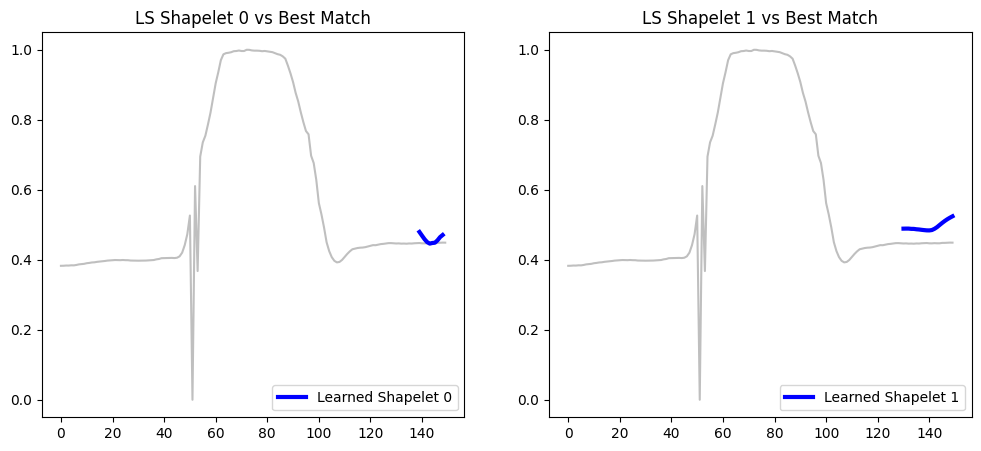

'\n================================================================================\nTHEORETICAL BACKGROUND: INTERPRETING LEARNED SHAPELETS\n================================================================================\n\n1. THE "IDEALIZED" PATTERN\nUnlike the Shapelet Transform (ST), which picks an existing slice of data, \nLearning Shapelets (LS) creates "idealized" versions of patterns. \nThe blue line you see is a mathematical construct that minimizes classification \nerror across the ENTIRE dataset, rather than being limited to one specific \ntraining sample.\n\n2. THE "LOCATE" MATHEMATICS\nThe function ls.locate() uses the same logic as the distance formula:\n\n    t0 = argmin_i Σ_{j=1}^{L} (T_{i+j-1} - S_j)^2\n\nIt returns the specific offset \'i\' where the learned shapelet S fits most \nsnugly into the series T. This demonstrates \nthe \'Translation Invariance\' of the model—it found the pattern regardless \nof where it appeared in the sequence.\n\n\n\n3. WHY DO THEY LOOK S

In [14]:
# 1. IDENTIFY LOCATIONS AND PATTERNS
# locate() returns the index 'i' where the distance was minimized for each series
predicted_locations = ls.locate(X_train_scaled)
# shapelets_ contains the actual numerical values (the 'weights') of the learned patterns
learned_shapelets = ls.shapelets_

plt.figure(figsize=(12, 5))
for i, s in enumerate(learned_shapelets):
    # 2. FIND THE REPRESENTATIVE EXAMPLE
    # transform() gives us the distance matrix; we find the series (row) 
    # that is most similar (minimum distance) to shapelet 'i'
    distances = ls.transform(X_train_scaled)[:, i]
    best_series_idx = np.argmin(distances)
    
    plt.subplot(1, 2, i + 1)
    # Plot the full background time series
    plt.plot(X_train_scaled[best_series_idx].ravel(), color='gray', alpha=0.5)
    
    # 3. OVERLAY THE LEARNED SHAPELET
    # t0 is the starting timestamp of the best match
    t0 = predicted_locations[best_series_idx, i]
    # We plot the shapelet starting at t0 to show the 'Alignment'
    plt.plot(np.arange(t0, t0 + len(s)), s.ravel(), color='blue', lw=3, label=f"Learned Shapelet {i}")
    
    plt.title(f"LS Shapelet {i} vs Best Match")
    plt.legend()
plt.show()

"""
================================================================================
THEORETICAL BACKGROUND: INTERPRETING LEARNED SHAPELETS
================================================================================

1. THE "IDEALIZED" PATTERN
Unlike the Shapelet Transform (ST), which picks an existing slice of data, 
Learning Shapelets (LS) creates "idealized" versions of patterns. 
The blue line you see is a mathematical construct that minimizes classification 
error across the ENTIRE dataset, rather than being limited to one specific 
training sample.

2. THE "LOCATE" MATHEMATICS
The function ls.locate() uses the same logic as the distance formula:
    
    t0 = argmin_i Σ_{j=1}^{L} (T_{i+j-1} - S_j)^2
    
It returns the specific offset 'i' where the learned shapelet S fits most 
snugly into the series T. This demonstrates 
the 'Translation Invariance' of the model—it found the pattern regardless 
of where it appeared in the sequence.



3. WHY DO THEY LOOK SMOOTH?
You may notice learned shapelets often look smoother or more regular than 
raw data. This is due to the 'Regularization' term in the loss function 
minimized during training:
    
    Loss = ClassificationError(y, ŷ) + λ * ||S||²
    
The regularization (λ) prevents the shapelets from becoming too noisy or 
'overfitting' to a single person's movement in the GunPoint data.

4. GPU & DEEP LEARNING PARALLEL
In a GPU-accelerated CNN context, this visualization is equivalent to 
performing 'Feature Map Visualization'. 
The learned shapelet is the 'Convolutional Kernel,' and the blue line shows 
where that kernel 'fired' (had the highest response) on the input signal.


"""

3. 2D Embedding and Accuracy

The embedding is created by transforming the time series into the distance space of the learned shapelets.

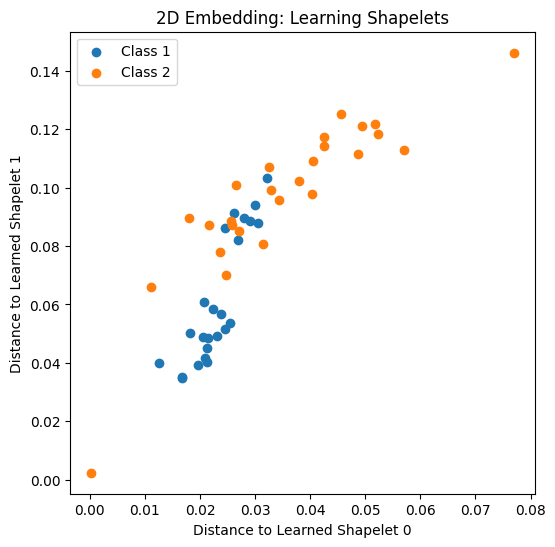

/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


LS Training Accuracy (2 shapelets): 0.5200


'\n================================================================================\nTHEORETICAL BACKGROUND: OPTIMIZED EMBEDDINGS\n================================================================================\n\n1. THE "LEARNED" COORDINATE SYSTEM\nUnlike the earlier Shapelet Transform (ST) exercise where we picked 2 snippets \nfrom the data, this plot uses 2 patterns that were specifically \'sculpted\' by \nthe algorithm to maximize class separation. \nEach axis represents the "similarity" to a synthetic ideal pattern.\n\n2. LINEAR SEPARABILITY\nThe Learning Shapelets model includes a final linear layer (Logistic Regression). \nMathematically, this means the model is trying to arrange the dots in this \nplot so that a single straight line can separate Class 1 from Class 2:\n\n    ŷ = σ( w₀ + w₁*d(T, S₁) + w₂*d(T, S₂) )\n\nWhere σ is the sigmoid function. If your scatter \nplot shows two distinct clusters, the model has achieved linear separability \nin the embedded space.\n\n\n\n3. 

In [15]:
# 1. GENERATE THE EMBEDDING
# We transform the raw time series into a vector of distances to the learned patterns.
# X_ls_embedded has shape (n_samples, 2), representing coordinates in 'Shapelet Space'.
X_ls_embedded = ls.transform(X_train_scaled)

plt.figure(figsize=(6, 6))
# 2. GROUP DATA BY CLASS
for label in np.unique(y_train):
    mask = (y_train == label)
    # Scatter plot where:
    # Axis 0 = Distance to the first learned pattern (Length 10)
    # Axis 1 = Distance to the second learned pattern (Length 20)
    plt.scatter(X_ls_embedded[mask, 0], X_ls_embedded[mask, 1], label=f"Class {label}")

plt.title("2D Embedding: Learning Shapelets")
plt.xlabel("Distance to Learned Shapelet 0")
plt.ylabel("Distance to Learned Shapelet 1")
plt.legend()
plt.show()

# 3. COMPUTE ACCURACY
# The .score() method uses the internal logistic regression layer to predict 
# classes and compare them against the ground truth 'y_train'.
train_acc = ls.score(X_train_scaled, y_train)
print(f"LS Training Accuracy (2 shapelets): {train_acc:.4f}")

"""
================================================================================
THEORETICAL BACKGROUND: OPTIMIZED EMBEDDINGS
================================================================================

1. THE "LEARNED" COORDINATE SYSTEM
Unlike the earlier Shapelet Transform (ST) exercise where we picked 2 snippets 
from the data, this plot uses 2 patterns that were specifically 'sculpted' by 
the algorithm to maximize class separation. 
Each axis represents the "similarity" to a synthetic ideal pattern.

2. LINEAR SEPARABILITY
The Learning Shapelets model includes a final linear layer (Logistic Regression). 
Mathematically, this means the model is trying to arrange the dots in this 
plot so that a single straight line can separate Class 1 from Class 2:
    
    ŷ = σ( w₀ + w₁*d(T, S₁) + w₂*d(T, S₂) )

Where σ is the sigmoid function. If your scatter 
plot shows two distinct clusters, the model has achieved linear separability 
in the embedded space.



3. THE MATH OF PERFORMANCE (.score)
When you run 'ls.score', the model performs a forward pass:
   a) It slides the learned kernels over the input series (Convolution).
   b) It finds the best match (Min-Pooling).
   c) It feeds those distances into the learned weights w to get a probability.
   d) If probability > 0.5, it predicts class 1; otherwise, class 0.

4. COMPARISON WITH RAW DATA
By compressing 150 timestamps into just 2 distances, we have significantly 
simplified the problem. This embedding acts 
as a 'Non-linear Dimensionality Reduction' specifically tuned for 
classification tasks.


"""

4. Improving Accuracy

To improve performance, we increase the n_shapelets_per_size parameter to capture more diverse local features.

In [16]:
# Try 5 shapelets for each length
# By increasing the diversity of lengths (10, 20, 30), we capture short 'twitches'
# and longer 'gestures' simultaneously.
ls_improved = LearningShapelets(n_shapelets_per_size={10: 5, 20: 5, 30: 5},
                                 max_iter=1000,
                                 random_state=42)

# The model now optimizes 15 different synthetic patterns (5 of each size)
# to minimize classification error.
ls_improved.fit(X_train_scaled, y_train)

# .score() evaluates how well this high-dimensional embedding separates the classes.
print(f"Improved Training Accuracy: {ls_improved.score(X_train_scaled, y_train):.4f}")

"""
================================================================================
THEORETICAL BACKGROUND: MODEL CAPACITY & SCALING
================================================================================

1. MULTI-SCALE FEATURE EXTRACTION
By providing a dictionary of sizes {10: 5, 20: 5, 30: 5}, the model performs 
multi-scale analysis. 
- Small shapelets (10) focus on high-frequency changes (noise or sharp twitches).
- Larger shapelets (30) capture global trends or longer phases of movement.



2. MATHEMATICAL COMPLEXITY
The embedding function Φ now maps the time series into a 15-dimensional space:
    Φ(T) = [d(T, S₁), ..., d(T, S₁₅)]
Each dimension represents the similarity to one of the 15 learned patterns.
As K (the number of shapelets) increases, the SVC or Logistic Regression layer 
can create more complex, non-linear decision boundaries.

3. GRADIENT DESCENT DYNAMICS
During .fit(), the GPU (if used) calculates gradients for all 15 patterns 
simultaneously. 
Each shapelet is updated based on its contribution to the total loss:
    S_new = S_old - η * (∂Loss / ∂S)
This is why the accuracy improves; the model has 15 different 'filters' 
to find evidence for a class instead of just 2.



4. PERFORMANCE VS. OVERFITTING
While more shapelets improve training accuracy, it also increases the risk of 
overfitting. 
The model might start 'learning' specific noise patterns unique to the 
training subjects rather than generalizable features.
The regularization term λ * ||S||² in the loss function is what prevents 
these 15 shapelets from becoming overly erratic.
"""

/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/tslearn/shapelets/shapelets.py:492: FutureWarning: The default value for 'scale' is set to False in version 0.4 to ensure backward compatibility, but is likely to change in a future version.
  warnings.warn("The default value for 'scale' is set to False "
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream lay

Improved Training Accuracy: 0.5200


---

---